<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/2_Use_a_pre_trained_model_for_image_classification_with_fine_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Download flower photos (5 classes, ~3670 images)
url = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
archive = keras.utils.get_file('flower_photos.tar', origin=url, extract=True)
# locate the extracted folder (works for any Keras version)
for root, dirs, files in os.walk(os.path.dirname(archive)):
    if os.path.basename(root) == 'flower_photos' and 'daisy' in dirs:
        data_dir = root; break
print(data_dir, os.listdir(data_dir))

IMG = (160, 160); BATCH = 32
train_ds = keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset='training',
                                                    seed=42, image_size=IMG, batch_size=BATCH)
val_ds   = keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset='validation',
                                                    seed=42, image_size=IMG, batch_size=BATCH)
class_names = train_ds.class_names
print(class_names)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE); val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
/root/.keras/datasets/flower_photos_extracted/flower_photos ['roses', 'sunflowers', 'tulips', 'LICENSE.txt', 'daisy', 'dandelion']
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
# 2. Load pre-trained base (no top classifier) and FREEZE it
base = keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights='imagenet')
base.trainable = False

# 3. Add our own classifier head
inputs = keras.Input(shape=IMG + (3,))
x = layers.RandomFlip('horizontal')(inputs)                 # light augmentation
x = layers.Rescaling(1./127.5, offset=-1)(x)                # MobileNetV2 expects pixels in [-1, 1]
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)
model = keras.Model(inputs, outputs)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# 4. STEP A - train only the new head (feature extraction)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 80s 819ms/step - accuracy: 0.7251 - loss: 0.7654 - val_accuracy: 0.8406 - val_loss: 0.4694
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 80s 866ms/step - accuracy: 0.8607 - loss: 0.3920 - val_accuracy: 0.8651 - val_loss: 0.3871
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 78s 849ms/step - accuracy: 0.8988 - loss: 0.3106 - val_accuracy: 0.8488 - val_loss: 0.4258


In [ ]:
# 5. STEP B - FINE-TUNING: unfreeze top layers of the base model
base.trainable = True
for layer in base.layers[:100]:        # keep first 100 layers frozen (generic features)
    layer.trainable = False
print("Trainable layers in base:", sum(l.trainable for l in base.layers))

model.compile(optimizer=keras.optimizers.Adam(1e-5),          # VERY small learning rate
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=3)

Trainable layers in base: 54
Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.7871 - loss: 0.5670 - val_accuracy: 0.8624 - val_loss: 0.4007
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.8764 - loss: 0.3852 - val_accuracy: 0.8774 - val_loss: 0.3784
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.8944 - loss: 0.3211 - val_accuracy: 0.8856 - val_loss: 0.3540


Validation accuracy after fine-tuning: 88.56%


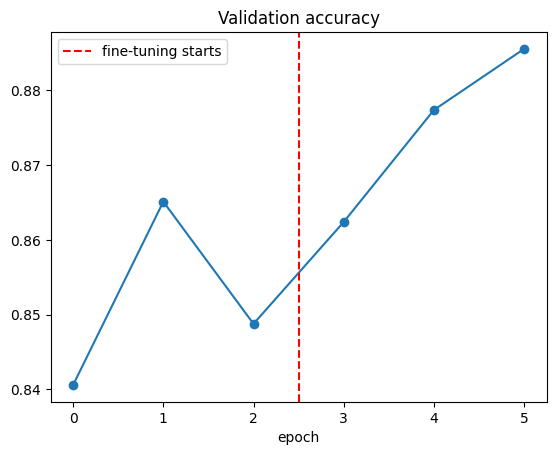

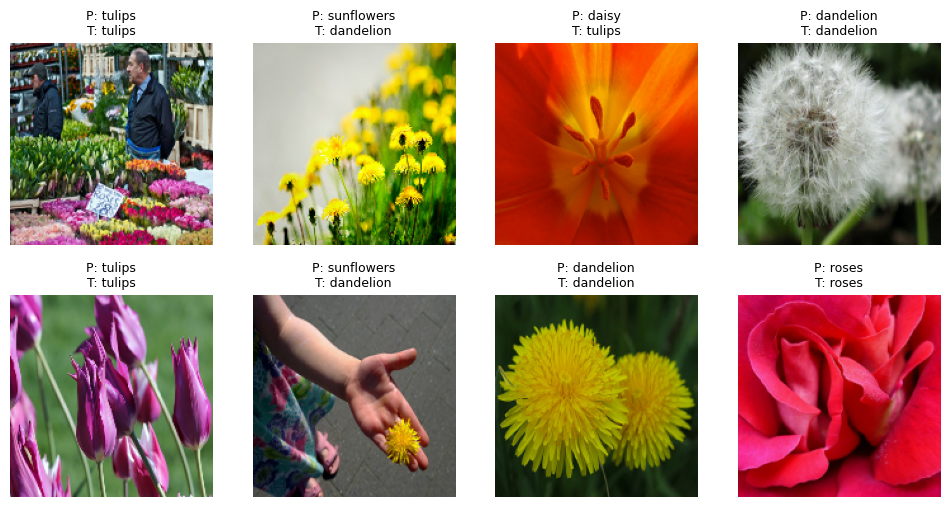

In [ ]:
# 6. Results
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy after fine-tuning: {acc*100:.2f}%")     # expect about 90%+

acc_all = h1.history['val_accuracy'] + h2.history['val_accuracy']
plt.plot(acc_all, marker='o'); plt.axvline(len(h1.history['val_accuracy']) - 0.5, color='r', ls='--', label='fine-tuning starts')
plt.title('Validation accuracy'); plt.xlabel('epoch'); plt.legend(); plt.show()

# predict a few validation images
images, labels = next(iter(val_ds))
pred = np.argmax(model.predict(images, verbose=0), axis=1)
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(f"P: {class_names[pred[i]]}\nT: {class_names[labels[i]]}", fontsize=9); plt.axis('off')
plt.show()

In [ ]:
1. What is the problem?
We want to classify flower photos into 5 types (daisy, dandelion, roses, sunflowers, tulips). We only have about 3,670 images, which is small. Training a big CNN from scratch on that little data would be slow and inaccurate.

2. What is the solution?
We use transfer learning: take a model that someone already trained on a huge dataset and reuse its knowledge for our small task.
Analogy: a person who already knows how to paint landscapes can learn to paint flowers much faster than a complete beginner. Their skill transfers.
3. Pre-trained model: MobileNetV2, trained on ImageNet (1.2 million images, 1000 classes). It already knows edges, textures, shapes and colours.
We remove its final layer (the 1000-class classifier) and add our own 5-class classifier.

Training happens in two stages:

	Stage		        What we do	         											Learning rate
Step A: Feature extraction	Freeze the whole MobileNetV2 (its weights don't change). Train only our new classifier.				0.001
Step B: Fine-tuning	        Unfreeze the top layers of MobileNetV2 and train them together with our classifier, to adapt them to flowers.	0.00001 (very small)

Why freeze first? Our new classifier starts with random weights and makes big mistakes at first. If the base model were unfrozen, those big errors would damage its good pre-trained weights.

Why a very small learning rate for fine-tuning? We want to nudge the pre-trained weights slightly, not destroy them.

Why unfreeze only the top layers? Early layers learn general things (edges, colours) that suit every image. Later layers learn task-specific things, so those are the ones worth adapting.

One-line answer for the examiner: "Fine-tuning means unfreezing some top layers of the pre-trained model and training them with a very low learning rate, so it adapts to our dataset."

########## CODE EXPLANATION->
1. url = '.../flower_photos.tgz'
archive = keras.utils.get_file('flower_photos.tar', origin=url, extract=True)
Downloads and unzips the flower dataset.

2.train_ds = keras.utils.image_dataset_from_directory(data_dir, validation_split=0.2, subset='training',
                                                    seed=42, image_size=IMG, batch_size=BATCH)
val_ds   = ... subset='validation' ...
Reads images from folders, where each folder name is the class name. 80% is used for training and 20% for validation. The same seed is used for both, so they don't overlap. Images are resized to 160×160.

Step 2: Load the pre-trained model and freeze it

base = keras.applications.MobileNetV2(input_shape=IMG+(3,), include_top=False, weights='imagenet')
base.trainable = False

weights='imagenet' loads the knowledge learned on ImageNet.
include_top=False removes the original 1000-class classifier.
trainable = False freezes the weights.

Step 3: Add our classifier

x = layers.RandomFlip('horizontal')(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)
model = keras.Model(inputs, outputs)

\Rescaling(1/127.5, offset=-1): pixel/127.5 − 1 turns 0–255 into −1 to 1.
training=False keeps the frozen base in inference mode.
GlobalAveragePooling replaces Flatten. It has no parameters and gives fewer overfitting problems.

Step 4: Step A, train only the new head

python
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=3)

Step 5: Step B, fine-tuning

python
base.trainable = True
for layer in base.layers[:100]:
    layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5), ...)   # note the tiny learning rate
h2 = model.fit(train_ds, validation_data=val_ds, epochs=3)
We unfreeze the whole base, then freeze the first 100 layers again. So only the last 54 layers train.
We must recompile after changing trainable, otherwise the change doesn't take effect.
The learning rate is 1e-5, which is 100 times smaller than before.

Step 6: Evaluate and predict. model.evaluate gives the validation accuracy. The graph has a red dashed line where fine-tuning starts. A few validation images are shown with predicted and true labels.

5. The output you will see
Class names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'].
Model summary. The base model shows as one block (mobilenetv2_1.00_160) and the total is about 2.26 million parameters, of which only about 6,405 are trainable in Step A.
Step A training: validation accuracy rises to roughly 88–92% within 3 epochs.
Trainable layers in base: 54.
Step B training: accuracy improves a little more, usually 1–4% higher.
Final validation accuracy printed, roughly 90–94%.
A graph of validation accuracy, with a dashed line at the fine-tuning start.
A grid of 8 flower images with P: (predicted) and T: (true) labels.

####BLOCK DIAGRAM###
       Load MobileNetV2
              |
              v
        Freeze Base Model
              |
              v
      Train New Classifier
       (Feature Extraction)
              |
              v
       Unfreeze Top Layers
              |
              v
        Small Learning Rate
          (0.00001)
              |
              v
          Fine-Tuning
              |
              v
        Evaluate Model


#### QUESTIONS ####
Questions the examiner may ask
What is transfer learning? Reusing a model trained on a large dataset for a new, smaller task.
Difference between feature extraction and fine-tuning? In feature extraction the *entire base stays frozen*. In fine-tuning some top layers are also trained.
Why such a low learning rate in fine-tuning? Large updates would destroy the useful pre-trained weights.
What does include_top=False mean? It removes the original ImageNet classifier so we can attach our own.
What is ImageNet? A dataset of about 1.2 million images in 1000 classes, used to pre-train models.
Why MobileNetV2? It is small, fast and accurate, so it suits Colab and mobile devices.
What does GlobalAveragePooling do? It averages each feature map to one number (5×5×1280 becomes 1280).
Why do we recompile the model? Changing which layers are trainable only takes effect after recompiling.
Other pre-trained models? VGG16, ResNet50, InceptionV3, DenseNet, EfficientNet.